In [1]:
import ee
import geemap
import ipywidgets as widgets
from datetime import datetime, timedelta
import pandas as pd
import matplotlib.pyplot as plt

# Initialize Earth Engine
ee.Authenticate()
ee.Initialize()


In [20]:
!jupyter labextension install @jupyter-widgets/jupyterlab-manager
  

^C


(Deprecated) Installing extensions with the jupyter labextension install command is now deprecated and will be removed in a future major version of JupyterLab.

Users should manage prebuilt extensions with package managers like pip and conda, and extension authors are encouraged to distribute their extensions as prebuilt packages 
Building jupyterlab assets (production, minimized)


In [2]:
# Create an interactive map
Map = geemap.Map(center=[0, 0], zoom=2)
Map.add_basemap('HYBRID')

# Add drawing controls
Map.draw_features

Map


Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], widget=SearchDataGUI(childr…

In [3]:
def calculate_cloud_stats(geometry):
    """Calculate cloud cover statistics for a given geometry."""
    
    # Get the current year and previous year
    current_year = datetime.now().year
    
    # Define the MODIS cloud collection
    collection = ee.ImageCollection('MODIS/061/MOD09GA') \
        .filterDate(f'{current_year-1}-01-01', f'{current_year}-12-31') \
        .select('state_1km')
    
    def extract_cloud_bits(image):
        """Extract cloud bits from the state_1km band."""
        QA = image.select('state_1km')
        cloud = QA.bitwiseAnd(1 << 10).neq(0)  # Extract cloud state
        return image.addBands(cloud.rename('cloud'))
    
    # Map the cloud extraction over the collection
    cloud_collection = collection.map(extract_cloud_bits)
    
    # Calculate cloud frequency
    cloud_freq = cloud_collection.select('cloud').mean().multiply(100)
    
    # Get cloud stats for the geometry
    stats = cloud_freq.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=geometry,
        scale=1000,
        maxPixels=1e9
    )
    
    # Calculate monthly statistics
    months = range(1, 13)
    monthly_stats = []
    
    for month in months:
        start_date = ee.Date.fromYMD(current_year-1, month, 1)
        end_date = start_date.advance(1, 'month')
        
        monthly_clouds = cloud_collection \
            .filterDate(start_date, end_date) \
            .select('cloud') \
            .mean() \
            .multiply(100)
            
        monthly_mean = monthly_clouds.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry,
            scale=1000,
            maxPixels=1e9
        ).get('cloud')
        
        monthly_stats.append({
            'month': month,
            'cloud_percentage': monthly_mean.getInfo()
        })
    
    # Convert to pandas DataFrame for plotting
    df = pd.DataFrame(monthly_stats)
    
    return {
        'annual_percentage': stats.get('cloud').getInfo(),
        'monthly_stats': df
    }

def plot_cloud_stats(stats):
    """Plot cloud cover statistics."""
    df = stats['monthly_stats']
    
    plt.figure(figsize=(12, 6))
    plt.plot(df['month'], df['cloud_percentage'], marker='o')
    plt.title('Monthly Cloud Cover Percentage')
    plt.xlabel('Month')
    plt.ylabel('Cloud Cover (%)')
    plt.grid(True)
    plt.xticks(range(1, 13))
    plt.show()
    
    print(f"\nAnnual Cloud Cover Statistics:")
    print(f"Average cloud cover: {stats['annual_percentage']:.2f}%")
    print(f"Estimated cloudy days per year: {(stats['annual_percentage'] * 365 / 100):.0f} days")


Calculating cloud cover statistics... This may take a few moments.


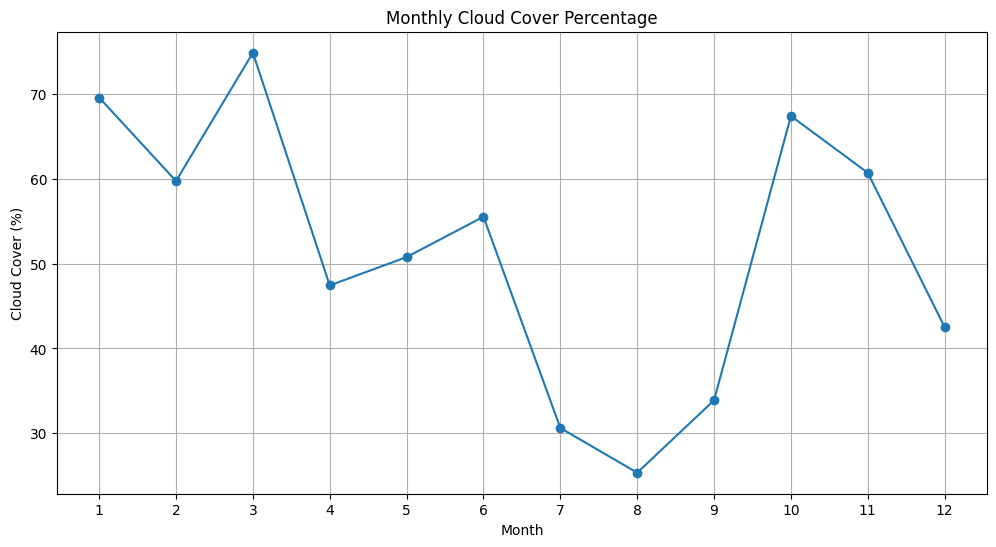


Annual Cloud Cover Statistics:
Average cloud cover: 52.12%
Estimated cloudy days per year: 190 days
Calculating cloud cover statistics... This may take a few moments.


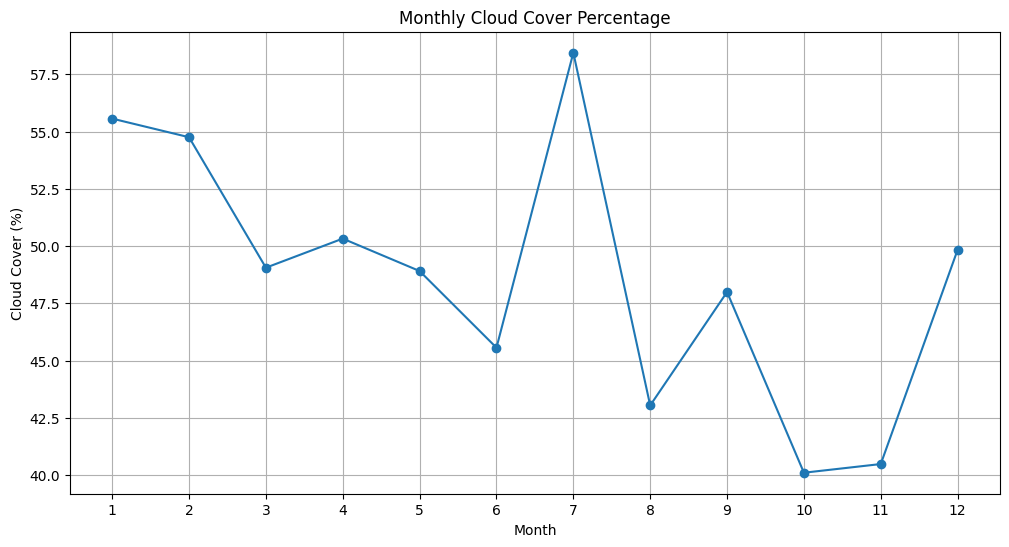


Annual Cloud Cover Statistics:
Average cloud cover: 49.99%
Estimated cloudy days per year: 182 days


In [8]:
# Get the drawn features and calculate statistics
# Get the drawn features and calculate statistics
if len(Map.draw_features) > 0:
    ee_feature = Map.draw_features[0]
    ee_geometry = ee_feature.geometry()
    print("Calculating cloud cover statistics... This may take a few moments.")
    stats = calculate_cloud_stats(ee_geometry)
    plot_cloud_stats(stats)
else:
    print("Please draw a polygon on the map first using the drawing tools.")

# Alternative: Use the last drawn feature
if Map.draw_last_feature is not None:
    ee_geometry = Map.draw_last_feature.geometry()
    print("Calculating cloud cover statistics... This may take a few moments.")
    stats = calculate_cloud_stats(ee_geometry)
    plot_cloud_stats(stats)
else:
    print("Please draw a polygon on the map first using the drawing tools.")